# Тюнинг линейной регрессии и ошибки

### О задании

В этом задании вы:
- обучите линейную регрессию, познакомитесь с метриками качества в задачах регресии

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split

## Часть 1. Линейная регрессия

Для начала загрузим данные и разделим их на обучающую и тестовую выборки в соотношении 7 к 3. Зачем так делать? Когда вы проверяете себя на данных на которых не обучались, вы можете быть уверены что не переобучились. Таким образом если качество на 70% датасета (оубчающей выборке) растёт, а на тестовой выборке падает, то модель начала запоминать датасет (переобучилась), вы что-то делаете не так.


In [2]:
data = load_diabetes()
X_train, X_test, y_train, y_test = train_test_split(data.data, data.target, train_size=0.7, random_state=241)

__Задание 1.__ Обучение линейной регрессии.

**(4 балла)**

Обучите линейную регрессию с $L_1$ (Lasso) и $L_2$ (Ridge) регуляризаторами (используйте параметры по умолчанию). Посмотрите, какое количество коэффициентов близко к 0 (степень близости к 0 определите сами из разумных пределов). Постройте график зависимости числа ненулевых коэффициентов от коэффицента регуляризации (перебирайте значения по логарифмической сетке от $10^{-3}$ до $10^3$).

Спойлер - при большом гиперпараметре регуляризации все параметры стремятся к нулю. На графике это должно быть видно.

Постройте графики коэффициентов регрессии от итерации обучения

In [3]:
from sklearn import datasets, linear_model
from sklearn.linear_model import Ridge, Lasso
import numpy as np

Число коэффициентов, близких к нулю (|w| < 1):
Ridge: 0
Lasso: 7


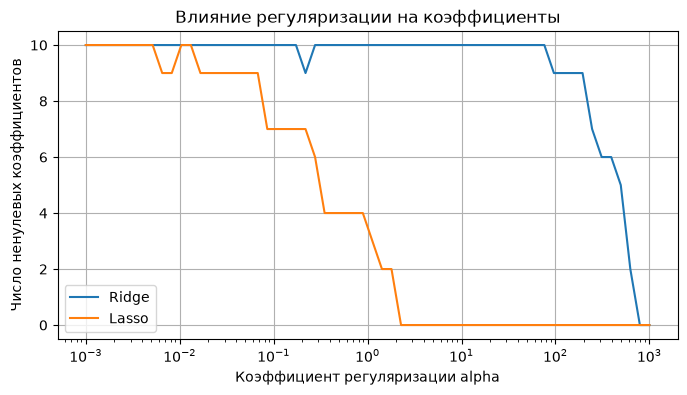

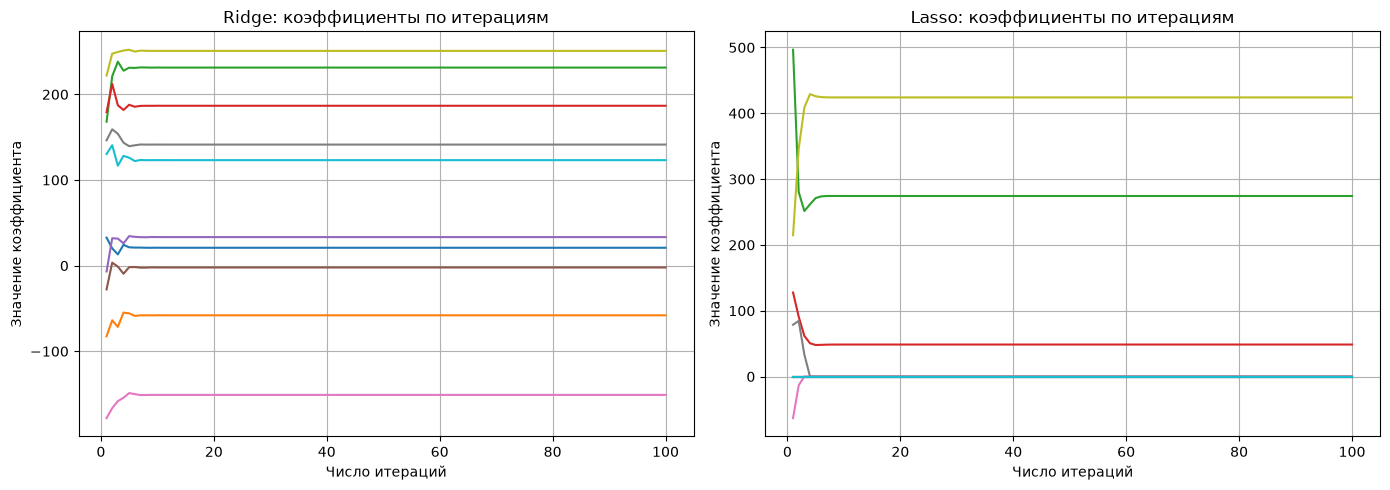

In [ ]:
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt
import warnings

# Модели с параметрами по умолчанию
ridge = Ridge().fit(X_train, y_train)
lasso = Lasso(max_iter=20000).fit(X_train, y_train)

threshold = 1.0
print("Число коэффициентов, близких к нулю (|w| < 1):")
print("Ridge:", np.sum(np.abs(ridge.coef_) < threshold))
print("Lasso:", np.sum(np.abs(lasso.coef_) < threshold))

alphas = np.logspace(-3, 3, 60)
ridge_nonzero = []
lasso_nonzero = []

for alpha in alphas:
    ridge_model = Ridge(alpha=alpha).fit(X_train, y_train)
    lasso_model = Lasso(alpha=alpha, max_iter=20000).fit(X_train, y_train)
    ridge_nonzero.append(np.sum(np.abs(ridge_model.coef_) >= threshold))
    lasso_nonzero.append(np.sum(np.abs(lasso_model.coef_) >= threshold))

plt.figure(figsize=(8, 4))
plt.semilogx(alphas, ridge_nonzero, label="Ridge")
plt.semilogx(alphas, lasso_nonzero, label="Lasso")
plt.xlabel("Коэффициент регуляризации alpha")
plt.ylabel("Число ненулевых коэффициентов")
plt.title("Влияние регуляризации на коэффициенты")
plt.grid(True)
plt.legend()
plt.show()

iterations = np.arange(1, 101)
ridge_history = []
lasso_history = []

with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)
    for iteration in iterations:
        ridge_step = Ridge(
            alpha=1.0,
            solver="sag",
            max_iter=iteration,
            tol=1e-12,
            random_state=241,
        ).fit(X_train, y_train)
        lasso_step = Lasso(
            alpha=1.0,
            max_iter=iteration,
            tol=1e-12,
        ).fit(X_train, y_train)
        ridge_history.append(ridge_step.coef_)
        lasso_history.append(lasso_step.coef_)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for feature in range(X_train.shape[1]):
    axes[0].plot(iterations, np.array(ridge_history)[:, feature])
    axes[1].plot(iterations, np.array(lasso_history)[:, feature])
axes[0].set_title("Ridge: коэффициенты по итерациям")
axes[1].set_title("Lasso: коэффициенты по итерациям")
for ax in axes:
    ax.set_xlabel("Число итераций")
    ax.set_ylabel("Значение коэффициента")
    ax.grid(True)
plt.tight_layout()
plt.show()


Посчитайте для Ridge-регрессии следующие метрики: $RMSE$, $MAE$, $R^2$.

In [5]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import cross_val_score


In [6]:
ridge_default = Ridge().fit(X_train, y_train)
y_pred_default = ridge_default.predict(X_test)

def regression_metrics(y_true, y_pred):
    return {
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAE": mean_absolute_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
    }

default_metrics = regression_metrics(y_test, y_pred_default)
print(pd.Series(default_metrics).round(4))


RMSE    58.3043
MAE     49.6028
R2       0.3599
dtype: float64


Подберите на обучающей выборке для Ridge-регрессии коэффициент регуляризации (перебирайте значения по логарифмической сетке от $10^{-3}$ до $10^3$) для каждой из метрик. Постройте графики зависимости фукнции потерь от коэффициента регуляризации. Посчитайте те же метрики снова. Заметно ли изменилось качество?

Лучшие значения alpha:
RMSE    0.002551
MAE     0.001264
R2      0.002019
dtype: float64


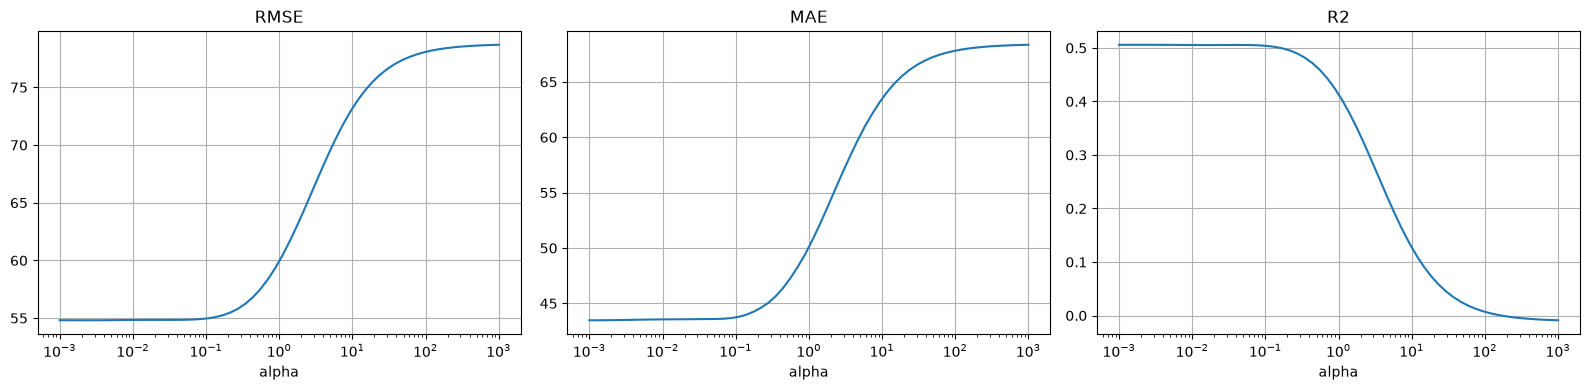

Метрики на тестовой выборке:


,alpha,RMSE,MAE,R2
Подбор по,,,,
RMSE,0.0026,55.8073,47.1100,0.4136
MAE,0.0013,55.8462,47.1462,0.4127
R2,0.0020,55.8207,47.1234,0.4133


После подбора RMSE уменьшилась заметно: значение alpha по умолчанию оказалось не лучшим для этого датасета.


In [ ]:
alphas = np.logspace(-3, 3, 60)
cv_rmse = []
cv_mae = []
cv_r2 = []

for alpha in alphas:
    model = Ridge(alpha=alpha)
    cv_rmse.append(-cross_val_score(model, X_train, y_train, cv=5, scoring="neg_root_mean_squared_error").mean())
    cv_mae.append(-cross_val_score(model, X_train, y_train, cv=5, scoring="neg_mean_absolute_error").mean())
    cv_r2.append(cross_val_score(model, X_train, y_train, cv=5, scoring="r2").mean())

best_alphas = {
    "RMSE": alphas[np.argmin(cv_rmse)],
    "MAE": alphas[np.argmin(cv_mae)],
    "R2": alphas[np.argmax(cv_r2)],
}
print("Лучшие значения alpha:")
print(pd.Series(best_alphas))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].semilogx(alphas, cv_rmse)
axes[0].set_title("RMSE")
axes[1].semilogx(alphas, cv_mae)
axes[1].set_title("MAE")
axes[2].semilogx(alphas, cv_r2)
axes[2].set_title("R2")
for ax in axes:
    ax.set_xlabel("alpha")
    ax.grid(True)
plt.tight_layout()
plt.show()

rows = []
for criterion, alpha in best_alphas.items():
    model = Ridge(alpha=alpha).fit(X_train, y_train)
    metrics = regression_metrics(y_test, model.predict(X_test))
    rows.append({"Подбор по": criterion, "alpha": alpha, **metrics})

tuned_results = pd.DataFrame(rows).set_index("Подбор по")
print("Метрики на тестовой выборке:")
display(tuned_results.round(4))
print("После подбора RMSE уменьшилась заметно: значение alpha по умолчанию оказалось не лучшим для этого датасета.")


__Задание 2.__ Поиск объектов-выбросов

**(4 балла)**

Как известно, MSE сильно штрафует за большие ошибки на объектах-выбросах. Посчитайте ошибки и посмотрите на их распределение (plt.hist). Что вы видите?

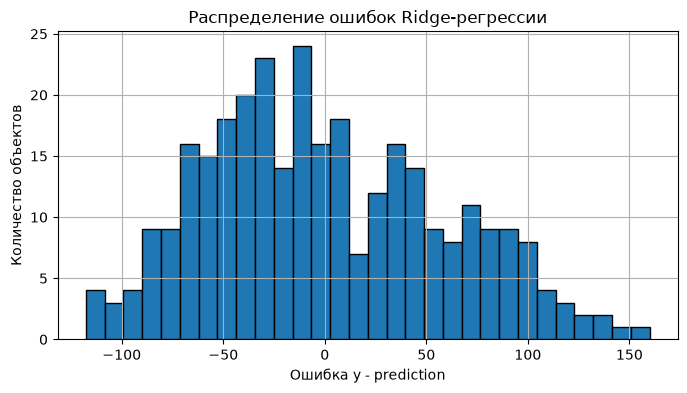

count    309.00
mean       0.00
std       58.42
min     -117.62
25%      -43.90
50%       -9.30
75%       40.93
max      159.91
dtype: float64
Распределение близко к колоколообразному, но в хвостах есть объекты с большими ошибками.


In [8]:
train_prediction = ridge_default.predict(X_train)
train_errors = y_train - train_prediction

plt.figure(figsize=(8, 4))
plt.hist(train_errors, bins=30, edgecolor="black")
plt.xlabel("Ошибка y - prediction")
plt.ylabel("Количество объектов")
plt.title("Распределение ошибок Ridge-регрессии")
plt.grid(True)
plt.show()

print(pd.Series(train_errors).describe().round(2))
print("Распределение близко к колоколообразному, но в хвостах есть объекты с большими ошибками.")


Попробуйте удалить объекты-выбросы из обучающей выборки (что считать или не считать выбросами на ваше усмотрение). Обучите модель заново и посмотрите на качество на отложенной выборке (учитывайте, что там тоже могут быть выбросы, с которыми вы ничего не можете сделать). Стало ли лучше? Чем вы можете объяснить это?

In [ ]:
outlier_limit = 2 * train_errors.std()
normal_mask = np.abs(train_errors) <= outlier_limit

X_train_clean = X_train[normal_mask]
y_train_clean = y_train[normal_mask]
print("Удалено объектов:", np.sum(~normal_mask), "из", len(y_train))

best_alpha = best_alphas["RMSE"]
ridge_tuned = Ridge(alpha=best_alpha).fit(X_train, y_train)
tuned_metrics = regression_metrics(y_test, ridge_tuned.predict(X_test))

ridge_clean = Ridge(alpha=best_alpha).fit(X_train_clean, y_train_clean)
clean_metrics = regression_metrics(y_test, ridge_clean.predict(X_test))

comparison = pd.DataFrame({
    "До удаления": tuned_metrics,
    "После удаления": clean_metrics,
})
display(comparison.round(4))

if clean_metrics["RMSE"] < tuned_metrics["RMSE"]:
    print("RMSE уменьшилась: удаление самых нетипичных обучающих объектов немного помогло.")
else:
    print("RMSE выросла: удалённые объекты содержали полезную информацию о возможных значениях цели.")
print("Тестовые выбросы оставлены, поэтому полностью избавиться от больших ошибок нельзя.")


Удалено объектов: 9 из 309


,До удаления,После удаления
RMSE,55.8073,56.9746
MAE,47.1100,48.0258
R2,0.4136,0.3888


RMSE выросла: удалённые объекты содержали полезную информацию о возможных значениях цели.
Тестовые выбросы оставлены, поэтому полностью избавиться от больших ошибок нельзя.


__Задание 3.__ Отчёт

**(2 балла)**

In [10]:
print("ОТЧЁТ")
print("1. Lasso зануляет коэффициенты заметно сильнее Ridge.")
print("2. Лучшие alpha по кросс-валидации:")
for metric, alpha in best_alphas.items():
    print(f"   {metric}: {alpha:.4g}")
print("3. Метрики Ridge по умолчанию:")
for metric, value in default_metrics.items():
    print(f"   {metric}: {value:.4f}")
print("4. Метрики настроенной Ridge до удаления выбросов:")
for metric, value in tuned_metrics.items():
    print(f"   {metric}: {value:.4f}")
print("5. Метрики после удаления выбросов:")
for metric, value in clean_metrics.items():
    print(f"   {metric}: {value:.4f}")
print("6. Подбор регуляризации улучшил качество, а удаление выбросов его ухудшило: удалённые строки были полезны модели.")


ОТЧЁТ
1. Lasso зануляет коэффициенты заметно сильнее Ridge.
2. Лучшие alpha по кросс-валидации:
   RMSE: 0.002551
   MAE: 0.001264
   R2: 0.002019
3. Метрики Ridge по умолчанию:
   RMSE: 58.3043
   MAE: 49.6028
   R2: 0.3599
4. Метрики настроенной Ridge до удаления выбросов:
   RMSE: 55.8073
   MAE: 47.1100
   R2: 0.4136
5. Метрики после удаления выбросов:
   RMSE: 56.9746
   MAE: 48.0258
   R2: 0.3888
6. Подбор регуляризации улучшил качество, а удаление выбросов его ухудшило: удалённые строки были полезны модели.
